In [2]:
!pip install kagglehub

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [7]:
import os
os.listdir(path)

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [9]:
import pandas as pd
df = pd.read_csv(f"{path}/WA_Fn-UseC_-Telco-Customer-Churn.csv")  # adjust to the actual filename
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Lab 2 — Data Cleaning & Exploratory Data Analysis

## Part 1 — The Business Problem

### Task 1 — Business Problem

The telecommunications company is losing customers to competitors and wants to understand which customers are more likely to leave. By analyzing customer information such as their services, contract, tenure, and billing details, the company can identify patterns related to churn. The likely target variable is **Churn**, because it indicates whether a customer left the company or not.

### Task 2 — Expected Predictors

#### Useful Predictors

1. **tenure** — Customers who have been with the company for a shorter or longer time may have different chances of churning.
2. **Contract** — Customers with different contract types may have different levels of commitment to the company.
3. **MonthlyCharges** — Higher or lower monthly charges may influence whether a customer decides to leave.
4. **InternetService** — The type of internet service may be related to customer satisfaction and churn.
5. **PaymentMethod** — Different payment methods may be associated with different customer churn patterns.

#### Expected Useless Predictors

1. **customerID** — It is an identifier and does not describe the customer's behavior or services.
2. **Second useless column** — To be determined after inspecting the dataset.

### Task 3 — Questions I Want the Data to Answer

1. Are customers with shorter tenure more likely to churn than customers who have been with the company for a longer time?

2. Does the type of contract or internet service have a noticeable relationship with customer churn?

## Part 2 — Exploring the Dataset Structure

In [10]:
df.shape

(7043, 21)

In [11]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Task 4 — Dataset Size and Feature Types

The dataset contains **7,043 customers and 21 columns**.

**Numerical features:**
- SeniorCitizen
- tenure
- MonthlyCharges
- TotalCharges

**Categorical features:**
- gender
- Partner
- Dependents
- PhoneService
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod
- Churn

The `TotalCharges` column represents a numerical amount, but it is currently stored as an `object` data type. This will need to be investigated and corrected during data cleaning.

### Task 5 — Identifier and Data Type Issues

The **customerID** column is an identifier rather than a predictive feature. It is used to uniquely identify each customer but does not describe customer behavior or services, so it should not be used as a predictor.

The **TotalCharges** column has a data type issue. It is currently stored as `object`, even though it represents a numerical billing amount. This column should be investigated and converted to a suitable numerical data type during the cleaning stage.

In [13]:
print("Gender:")
print(df["gender"].unique())

print("\nContract:")
print(df["Contract"].unique())

print("\nInternetService:")
print(df["InternetService"].unique())

Gender:
['Female' 'Male']

Contract:
['Month-to-month' 'One year' 'Two year']

InternetService:
['DSL' 'Fiber optic' 'No']


### Task 6 — Unique Values of Categorical Columns

I selected **gender**, **Contract**, and **InternetService** to inspect their unique values.

- **gender:** Female, Male
- **Contract:** Month-to-month, One year, Two year
- **InternetService:** DSL, Fiber optic, No

The categories in these three columns look expected and consistent. I did not find any obvious unexpected values, spelling differences, or inconsistent formatting.

## Part 3 — Investigating Data Quality

In [14]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [15]:
df.isnull().mean() * 100

,0
customerID,0.0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0


In [16]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing

,Missing Count,Missing Percentage
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [17]:
missing[missing["Missing Count"] > 0]

,Missing Count,Missing Percentage


### Task 7 — Missing Values

The dataset contains **0 missing values in every column**, so the missing-value percentage is **0.0% for every column**.

Since no null values were detected using `isnull()`, there are no missing-value problems that require action based on this check. Therefore, I do not need to remove rows or fill missing values at this stage.

However, `TotalCharges` is stored as an `object` data type even though it represents a numerical amount. This is a data-type issue rather than a missing-value issue, so it will be investigated separately during the data-cleaning stage.

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df["customerID"].duplicated().sum()

np.int64(0)

### Task 8 — Duplicate Rows and Duplicate Customer IDs

The dataset contains **0 fully duplicated rows** and **0 duplicate customer IDs**.

These are different issues. A duplicate row means that an entire customer record is repeated, while a duplicate customer ID could occur even when the other information in the rows is different. In this dataset, neither problem was found, so no duplicate records need to be removed based on these checks.

In [20]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [21]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [22]:
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

df.loc[total_charges_numeric.isna(), ["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


### Task 9 — Suspicious or Inconsistently Formatted Values

I found a data-quality issue in the **TotalCharges** column. Although TotalCharges represents a numerical billing amount, the column is stored as an `object` data type and contains **11 blank string values**.

I found this by checking for empty strings using `str.strip().eq("")`, which returned 11 values. I then used `pd.to_numeric(..., errors="coerce")`, which also identified 11 values that could not be converted to numbers. Inspecting these rows showed that all 11 customers have **tenure = 0** and a blank `TotalCharges` value.

These blank strings should be investigated and handled during the data-cleaning stage because they prevent TotalCharges from being treated as a proper numerical feature.

## Part 4 — Data Cleaning Decisions

### Task 10 — Data Cleaning Decisions

| Problem | Decision | Method Used | Reason |
|---|---|---|---|
| `TotalCharges` is stored as `object` instead of numeric | Convert it to a numeric data type | `pd.to_numeric()` | TotalCharges represents a billing amount, so it should be stored as a numerical value for analysis. |
| 11 `TotalCharges` values are blank strings | Treat the blank values as 0 | Replace blank strings with `0` before numeric conversion | All 11 affected customers have `tenure = 0`, which indicates they are new customers with no accumulated tenure. A total charge of 0 is therefore a reasonable interpretation for these records. |
| No fully duplicated rows were found | No action | `df.duplicated().sum()` | There are 0 duplicate rows, so removing duplicates is unnecessary. |
| No duplicate customer IDs were found | No action | `df["customerID"].duplicated().sum()` | Every customer ID is unique, so no records need to be removed for duplicate IDs. |
| `customerID` is an identifier rather than a predictive feature | Remove it from the cleaned ML dataset | `drop()` | The identifier distinguishes customers but does not provide meaningful customer behavior or service information for prediction. |

In [23]:
clean_df = df.copy()


clean_df["TotalCharges"] = clean_df["TotalCharges"].str.strip()

clean_df["TotalCharges"] = clean_df["TotalCharges"].replace("", "0")


clean_df["TotalCharges"] = pd.to_numeric(clean_df["TotalCharges"])

clean_df = clean_df.drop_duplicates()

clean_df = clean_df.drop(columns=["customerID"])

clean_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
print("Missing values:")
print(clean_df.isnull().sum())

print("\nTotalCharges data type:")
print(clean_df["TotalCharges"].dtype)

print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

print("\nCustomerID present:")
print("customerID" in clean_df.columns)

Missing values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type:
float64

Duplicate rows:
22

CustomerID present:
False


In [25]:
clean_df[clean_df["tenure"] == 0][["tenure", "TotalCharges"]].head(15)

,tenure,TotalCharges
488,0,0.0
753,0,0.0
936,0,0.0
1082,0,0.0
1340,0,0.0
3331,0,0.0
3826,0,0.0
4380,0,0.0
5218,0,0.0
6670,0,0.0


In [26]:
print("Duplicate rows in original dataset:", df.duplicated().sum())
print("Duplicate customer IDs in original dataset:", df["customerID"].duplicated().sum())

print("Duplicate rows in clean_df after removing customerID:", clean_df.duplicated().sum())

Duplicate rows in original dataset: 0
Duplicate customer IDs in original dataset: 0
Duplicate rows in clean_df after removing customerID: 22


In [29]:
duplicate_features = clean_df[clean_df.duplicated(keep=False)]

duplicate_features.head(10)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
22,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes
100,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.20,20.20,No
542,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
646,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
662,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.05,20.05,No
690,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,No
964,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,45.70,45.70,Yes
976,Male,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.90,69.90,Yes
1243,Male,0,No,No,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,45.30,45.30,Yes
1338,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.15,20.15,Yes


In [30]:
print("Original duplicate rows:", df.duplicated().sum())
print("Original duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nTotalCharges data type after cleaning:", clean_df["TotalCharges"].dtype)

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum().sum())

print("\nCustomerID present after cleaning:", "customerID" in clean_df.columns)

Original duplicate rows: 0
Original duplicate customer IDs: 0

TotalCharges data type after cleaning: float64

Missing values after cleaning:
0

CustomerID present after cleaning: False


### Task 11 — Cleaning Verification

The cleaning steps successfully resolved the identified data-quality issues.

- The original dataset had **0 duplicate rows** and **0 duplicate customer IDs**, so no duplicate records were removed.
- The 11 blank `TotalCharges` values were replaced with 0 after confirming that all affected customers had `tenure = 0`.
- `TotalCharges` was successfully converted from `object` to `float64`.
- There are **0 missing values** after cleaning.
- `customerID` was removed because it is an identifier rather than a predictive feature.

After removing `customerID`, 22 rows have identical remaining feature values. These were not removed because they represent different customers and the original dataset contained no duplicate records.

## Part 5 — Univariate EDA

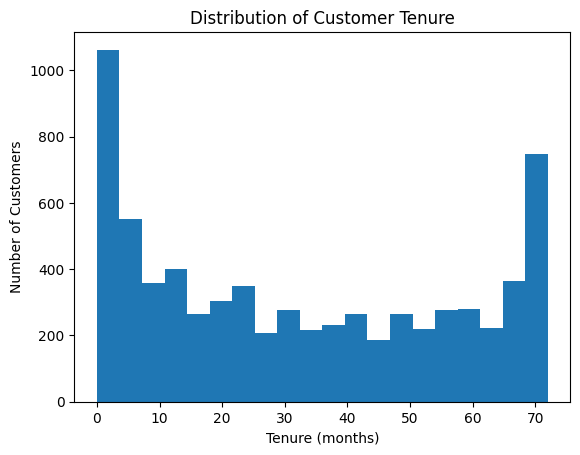

In [31]:
import matplotlib.pyplot as plt

clean_df["tenure"].plot(kind="hist", bins=20)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.show()

### Interpretation — Customer Tenure

The distribution of customer tenure is uneven, with a large concentration of customers at very low tenure and another noticeable concentration near 70 months. This suggests that the dataset contains many newer customers as well as a substantial group of long-term customers.

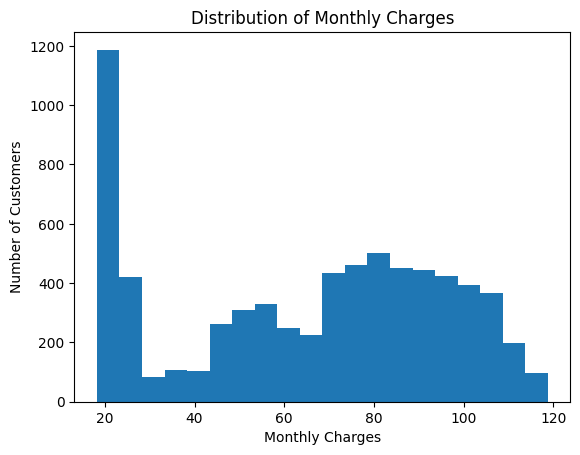

In [33]:
clean_df["MonthlyCharges"].plot(kind="hist", bins=20)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

### Interpretation — Monthly Charges

The distribution of monthly charges is uneven, with a very large concentration of customers at the lower charge range around $20–$30 and another broad concentration between about $70 and $110. This suggests that customers have different pricing levels, possibly because they subscribe to different combinations of services.

In [34]:
clean_df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [35]:
clean_df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


### Task 14 — Churn Distribution

The dataset contains **5,174 non-churned customers (73.46%)** and **1,869 churned customers (26.54%)**. Therefore, the target variable `Churn` is **imbalanced**, because the non-churned customers make up a much larger proportion of the dataset than the churned customers.

### Task 15 — Why Class Imbalance Matters

Class imbalance matters because a classification model may become biased toward the majority class, which in this dataset is the non-churned customers. As a result, the model could appear to perform well overall while doing a poor job of identifying customers who actually churn.

## Part 7 — Bivariate Analysis: Features vs. Churn

### Task 16 — Categorical Features vs. Churn

I will investigate two categorical features, `Contract` and `InternetService`, against the target variable `Churn`. For each feature, I will compare the churn rate across its categories and record the observation, evidence, and a possible explanation.

In [36]:
contract_churn = pd.crosstab(
    clean_df["Contract"],
    clean_df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


#### Contract vs. Churn — Observation / Evidence / Possible Explanation

- **Observation:** Customers with month-to-month contracts have the highest churn rate, while customers with two-year contracts have the lowest churn rate.
- **Evidence:** The churn rate is **42.71%** for month-to-month customers, **11.27%** for one-year customers, and only **2.83%** for two-year customers.
- **Possible Explanation:** Customers on month-to-month contracts may have less commitment to the company and may find it easier to switch to a competitor, while longer contracts may encourage customers to stay.

In [37]:
internet_churn = pd.crosstab(
    clean_df["InternetService"],
    clean_df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


#### InternetService vs. Churn — Observation / Evidence / Possible Explanation

- **Observation:** Customers with fiber optic internet have the highest churn rate, while customers without internet service have the lowest churn rate.
- **Evidence:** The churn rate is **18.96%** for DSL customers, **41.89%** for fiber optic customers, and **7.40%** for customers with no internet service.
- **Possible Explanation:** Fiber optic customers may have higher charges or different service expectations, which could be associated with greater churn. Customers without internet service have a much lower churn rate, possibly because they have fewer internet-related services that could influence their decision to leave.

### Task 17 — Numerical Features vs. Churn

I will investigate two numerical features, `tenure` and `MonthlyCharges`, against the target variable `Churn`. Boxplots will be used to compare the distributions of these numerical features between customers who churned and those who did not.

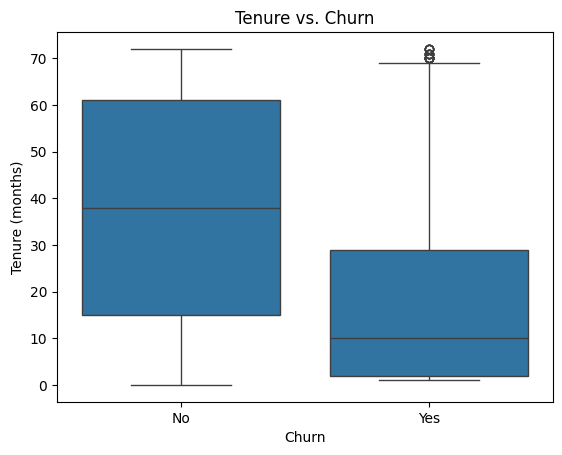

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x="Churn", y="tenure", data=clean_df)

plt.title("Tenure vs. Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

#### Tenure vs. Churn — Observation / Evidence / Possible Explanation

- **Observation:** Customers who churned generally have shorter tenure than customers who did not churn.
- **Evidence:** The median tenure for non-churned customers is around **38 months**, while the median tenure for churned customers is around **10 months**. The churned group is concentrated more heavily at lower tenure values.
- **Possible Explanation:** Newer customers may be less committed to the company and may be more likely to leave before developing a long-term relationship with the company.

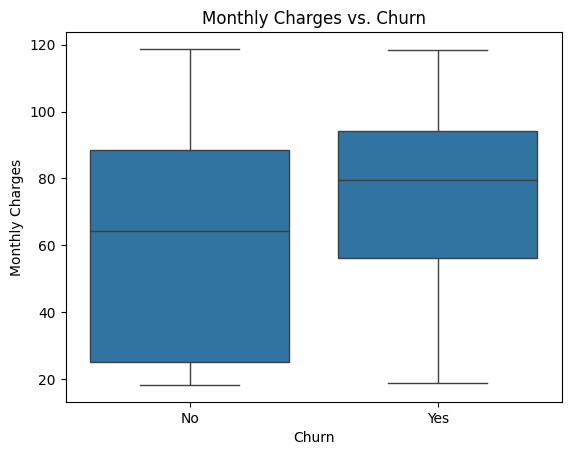

In [39]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=clean_df)

plt.title("Monthly Charges vs. Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

#### MonthlyCharges vs. Churn — Observation / Evidence / Possible Explanation

- **Observation:** Customers who churned generally have higher monthly charges than customers who did not churn.
- **Evidence:** The median monthly charge for non-churned customers is around **$65**, while the median for churned customers is around **$80**. The churned group is concentrated more heavily at higher monthly charge values.
- **Possible Explanation:** Customers paying higher monthly charges may be more sensitive to the cost of their services or may have higher service expectations, which could increase the likelihood of leaving.

## Part 8 — Correlation & Feature Relationships

### Task 18 — Correlation Matrix

I will compute and visualize the correlation matrix of the numerical features to identify which pairs of numerical features appear to be most strongly related.

In [40]:
correlation_matrix = clean_df.corr(numeric_only=True)

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000


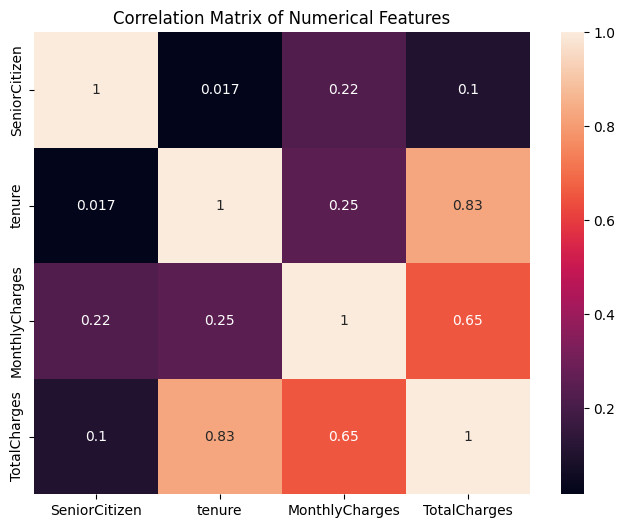

In [41]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

#### Task 18 — Correlation Matrix Interpretation

- **Observation:** The strongest correlation is between `tenure` and `TotalCharges`, followed by the correlation between `MonthlyCharges` and `TotalCharges`.
- **Evidence:** `tenure` and `TotalCharges` have a correlation of **0.826**, while `MonthlyCharges` and `TotalCharges` have a correlation of **0.651**. The correlation between `tenure` and `MonthlyCharges` is much weaker at **0.248**.
- **Possible Explanation:** Customers who have stayed with the company longer have had more time to accumulate total charges, which explains the strong relationship between `tenure` and `TotalCharges`. Similarly, customers with higher monthly charges are likely to accumulate higher total charges over time.

### Task 19 — Correlation vs. Causation

Correlation does not imply causation because two features can be strongly related without one directly causing the other. Highly correlated features can cause redundancy in a future model, which may make it harder to interpret the individual contribution of each feature and can create issues for some modeling methods.

## Part 9 — Data Leakage Awareness

### Task 20 — Inspecting for Data Leakage

Before building a classification model, I will inspect the dataset columns for information that could only be known after a customer has already churned, as well as columns that are purely identifiers. Such columns should not be used as predictive features because they would not represent information realistically available at the time of prediction.

In [42]:
print("Columns in the cleaned dataset:")
print(clean_df.columns.tolist())

Columns in the cleaned dataset:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [43]:
for column in clean_df.columns:
    print(column)

gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


#### Task 20 — Data Leakage and Identifier Assessment

- **Target variable:** `Churn` is the outcome we want to predict, so it must not be used as an input feature.
- **Identifier:** `customerID` is a purely identifying column and was removed from the cleaned dataset because it does not describe customer behavior or services.
- **Potential data leakage:** After inspecting the remaining columns, I did not find an obvious feature that could only be known after a customer had already churned. The remaining features describe customer demographics, services, contract details, tenure, and billing information that could reasonably be available before prediction.

### Task 21 — Consequences of Data Leakage

If a data-leakage column were included in the model's input features, the model could use information that would not actually be available at the time a prediction is made. This could make the model appear artificially accurate during training and evaluation, but its performance would likely be much worse when used on real future customers.

## Part 10 — ML-Readiness Checklist

### Task 22 — ML-Readiness Checklist

The following table summarizes the final role and action for every column in the dataset before machine learning.

| Column | Type | Role | Action | Reason |
|---|---|---|---|---|
| customerID | Identifier | — | Remove | It is only an identifier and does not provide useful customer behavior information for prediction. |
| gender | Categorical | Feature | Keep | It describes a customer characteristic and can be used as a predictive feature. |
| SeniorCitizen | Numerical | Feature | Keep | It is a numerical customer characteristic that may contain useful information for predicting churn. |
| Partner | Categorical | Feature | Keep | It describes the customer's relationship status and may be related to churn. |
| Dependents | Categorical | Feature | Keep | It provides information about the customer's household situation and may help predict churn. |
| tenure | Numerical | Feature | Keep | Customer tenure is a meaningful numerical feature and showed a relationship with churn. |
| PhoneService | Categorical | Feature | Keep | It describes whether the customer has phone service and may provide predictive information. |
| MultipleLines | Categorical | Feature | Keep | It describes the customer's phone-service configuration and may help predict churn. |
| InternetService | Categorical | Feature | Keep | Internet service type showed differences in churn rates across categories. |
| OnlineSecurity | Categorical | Feature | Keep | It describes an additional service and may contain useful information for predicting churn. |
| OnlineBackup | Categorical | Feature | Keep | It describes an additional service and may contain useful information for predicting churn. |
| DeviceProtection | Categorical | Feature | Keep | It describes an additional service and may contain useful information for predicting churn. |
| TechSupport | Categorical | Feature | Keep | It describes an additional service and may contain useful information for predicting churn. |
| StreamingTV | Categorical | Feature | Keep | It describes the customer's service usage and may provide predictive information. |
| StreamingMovies | Categorical | Feature | Keep | It describes the customer's service usage and may provide predictive information. |
| Contract | Categorical | Feature | Keep | Contract type showed a strong difference in churn rates across categories. |
| PaperlessBilling | Categorical | Feature | Keep | It describes the customer's billing arrangement and may provide predictive information. |
| PaymentMethod | Categorical | Feature | Keep | It describes how the customer pays and may provide useful information for predicting churn. |
| MonthlyCharges | Numerical | Feature | Keep | It represents the customer's monthly billing amount and showed differences between churn groups. |
| TotalCharges | Numerical | Feature | Keep | It represents the customer's accumulated billing amount. It was converted from object to numeric during cleaning. |
| Churn | Categorical | Target | Keep | It is the target variable that the future classification model will predict. |

# Part 11 — Building the Clean Dataset

In this section, I will finalize the cleaned dataframe `clean_df` using the cleaning decisions made earlier. The cleaned dataset will have the correct data types, handled missing values, and irrelevant identifier columns removed.

### Task 23 — Produce and Save the Clean Dataset

The final cleaned dataframe will be saved as `clean_churn.csv` so that it can be used directly in the next lab.

In [44]:
clean_df.to_csv("clean_churn.csv", index=False)

print("Clean dataset saved as clean_churn.csv")
print("Shape:", clean_df.shape)

Clean dataset saved as clean_churn.csv
Shape: (7043, 20)


### Task 24 — Final Verification of the Clean Dataset

The `clean_df.info()` output will be used to verify that the cleaned dataset has the expected data types and that the final dataset contains the required columns and records.

In [45]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


### Task 24 — Final Verification of the Clean Dataset

The final `clean_df.info()` output confirms that the cleaned dataset contains **7,043 records and 20 columns**, with **no missing values** in any column. The `TotalCharges` column has been successfully converted to the `float64` data type, and the `customerID` identifier has been removed. The cleaned dataframe is therefore ready for use in the next lab.

# Part 12 — Key Findings & Final Reflection

This section summarizes the main findings discovered during the data cleaning and exploratory data analysis. The findings are based on the evidence observed in the dataset and the analyses performed in the previous sections.

### Task 25 — Five Key Findings

#### Finding 1 — Data Quality Issue in TotalCharges

**Observation:** The `TotalCharges` column contained blank values and was stored as an `object` data type instead of a numerical type.

**Evidence:** The investigation found **11 blank `TotalCharges` values**, and all 11 affected customers had **tenure = 0**. The column was later converted successfully to `float64`.

**Interpretation:** These blank values were a data-quality issue that needed to be handled before analysis and machine learning. Because the affected customers had zero tenure, their blank total charges were treated as zero.

---

#### Finding 2 — Churn Is Imbalanced

**Observation:** Most customers in the dataset did not churn.

**Evidence:** There were **5,174 non-churned customers (73.46%)** and **1,869 churned customers (26.54%)**.

**Interpretation:** The target variable is imbalanced toward the non-churned class. This means identifying the smaller churned group will be particularly important in a future classification model.

---

#### Finding 3 — Contract Type Has a Strong Relationship with Churn

**Observation:** Customers with month-to-month contracts have a much higher churn rate than customers with longer contracts.

**Evidence:** The churn rate was **42.71%** for month-to-month customers, **11.27%** for one-year customers, and **2.83%** for two-year customers.

**Interpretation:** Longer contracts are associated with much lower churn, possibly because customers with longer commitments are less likely to switch to another provider.

---

#### Finding 4 — Shorter Tenure Is Associated with Churn

**Observation:** Customers who churned generally had much shorter tenure than customers who stayed.

**Evidence:** The median tenure was approximately **10 months** for churned customers compared with approximately **38 months** for non-churned customers.

**Interpretation:** Newer customers appear more likely to churn, possibly because they have had less time to develop a long-term relationship with the company.

---

#### Finding 5 — Internet Service Type Is Related to Churn

**Observation:** Churn rates differed considerably across internet service categories, with fiber optic customers showing the highest churn rate.

**Evidence:** The churn rate was **18.96%** for DSL customers, **41.89%** for fiber optic customers, and **7.40%** for customers with no internet service.

**Interpretation:** Internet service type appears to be associated with customer churn. The higher churn among fiber optic customers may be related to differences in pricing, service expectations, or other customer characteristics.

### Task 26 — Final Reflection

#### 1. What was the most important data-quality issue you found?

The most important data-quality issue was the `TotalCharges` column. It was stored as an `object` instead of a numerical data type and contained **11 blank values**. These blank values were found in customers with `tenure = 0`, so they were treated as zero during cleaning.

#### 2. What was the most interesting pattern you discovered?

The most interesting pattern was the strong relationship between contract type and churn. Customers with month-to-month contracts had a much higher churn rate (**42.71%**) compared with one-year (**11.27%**) and two-year (**2.83%**) contracts.

#### 3. Which feature seems most useful for predicting churn?

`Contract` appears to be one of the most useful features because the churn rate differs greatly between its categories. `tenure` also appears useful because customers who churned had a much lower median tenure than customers who did not churn.

#### 4. Which feature should probably not be used, and why?

`customerID` should not be used as a predictive feature because it is only an identifier. It distinguishes customers but does not provide meaningful information about their services, behavior, or likelihood of churn.

#### 5. What preprocessing will be required before ML modeling?

Before machine learning, categorical features will need to be converted into a numerical representation that the model can use. Numerical features may also need appropriate scaling depending on the model, and the target variable will need to be prepared for classification.

#### 6. What would you do next if you had another 3 hours?

I would investigate more customer segments and create additional visualizations to understand which combinations of customer characteristics are associated with higher churn. I would also prepare the cleaned dataset for the classification modeling work planned for the next lab.